# 2024 OPM FEVS – Gruplara Göre Kritik Sorular

Her grup (ajans, ajans kümesi, demografik kategori) için:

| Ölçüt | Tanım |
|---|---|
| **En düşük puanlı soru** | Ağırlıklı % pozitif değeri en düşük madde |
| **Ayrılmayla en ilişkili soru** | Madde puanı (1–5) ile ayrılma etiketi (1 = ayrılmayı düşünüyor) arasındaki **ağırlıklı Pearson korelasyonu** mutlak değerce en büyük madde. Negatif r = puan düştükçe ayrılma niyeti artıyor |
| **Öncelikli soru** | Hem düşük puanlı hem ayrılmayla güçlü ilişkili madde: `öncelik = |r| × (% negatif + % nötr)`. Yani "iyileştirilirse ayrılmayı en çok azaltabilecek" aday |

> **Dikkat:** Korelasyon nedensellik değildir. "Bu soru düzelirse ayrılma azalır" demek için deneysel / nedensel analiz gerekir; burada **ilişki** raporlanıyor.
> Etiketi (DLEAVING) boş olan satırlar analize girmez. Gruplama değişkeni boş (maskelenmiş) olanlar ayrı bir grup olarak gösterilir.
> Ayrılma niyetinin neredeyse eş anlamlısı olan genel memnuniyet maddeleri Q46 ("kurumumu tavsiye ederim"), Q70 ("işimden genel olarak memnunum") ve Q72 ("kurumumdan memnunum") ayrılmanın *nedeni* değil, aynı tutumun *sonucu*dur; bu yüzden ayrıca işaretlenir; sonuçlar bu ikisi **hariç** de verilir.

In [1]:
from pathlib import Path
from textwrap import fill
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

pd.set_option("display.max_columns", 100); pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 70); pd.set_option("display.max_rows", 200)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":          # notebook'lar notebooks/ klasöründen çalışır
    ROOT = ROOT.parent
DATA, FIG, TAB = ROOT / "data", ROOT / "reports" / "figures", ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

def kaydet(ad):
    """Grafiği reports/figures klasörüne kaydeder ve gösterir."""
    plt.savefig(FIG / f"{ad}.png", dpi=110, bbox_inches="tight")
    plt.show()
df = pd.read_pickle(DATA / "fevs2024_clean.pkl")
cb = pd.read_excel(DATA / "2024" / "2024_OPM_FEVS_PRDF_Codebook.xlsx", sheet_name="Survey Items")
cb["VARIABLE"] = cb["VARIABLE"].str.strip()
text_map = cb.groupby("VARIABLE")["ITEM TEXT"].first().str.strip().to_dict()

Q16_COLS = [f"Q16_{i}" for i in range(1, 7)]
LIKERT_COLS = [c for c in df.columns if c.startswith("Q") and c not in Q16_COLS and c != "Q91"]
PROXY = ["Q46", "Q70", "Q72"]     # sonuç (memnuniyet) maddeleri – hedefe çok yakın

df = df[df["DLEAVING"].notna()].copy()
df["y"] = (df["DLEAVING"] != "No").astype(float)
print(f"Etiketli satır: {len(df):,}")

SHORT = {"AF": "Hava Kuvvetleri", "AG": "Tarım (USDA)", "AM": "USAID", "AR": "Kara Kuvvetleri (Army)",
         "BG": "PBGC", "BO": "OMB", "CM": "Ticaret (DOC)", "CT": "CFTC", "CU": "NCUA",
         "DD": "DoD Ajansları (OSD)", "DJ": "Adalet (DOJ)", "DL": "Çalışma (DOL)", "DN": "Enerji (DOE)",
         "DR": "FERC", "ED": "Eğitim (ED)", "EE": "EEOC", "EP": "EPA", "FT": "FTC", "GS": "GSA",
         "HE": "Sağlık (HHS)", "HS": "İç Güvenlik (DHS)", "HU": "Konut (HUD)", "IB": "USAGM",
         "IN": "İçişleri (DOI)", "NF": "NSF", "NL": "NLRB", "NQ": "NARA", "NU": "NRC",
         "NV": "Deniz Kuvvetleri (Navy)", "OM": "OPM", "SB": "SBA", "ST": "Dışişleri (State)",
         "SZ": "Sosyal Güvenlik (SSA)", "TD": "Ulaştırma (DOT)", "TR": "Hazine (Treasury)", "XX": "Diğer ajanslar"}
# 03_ajans_benzerlik notebook'undaki profil şekli kümeleri
KUME = {**dict.fromkeys(["BG", "CM", "CU", "DL", "DR", "GS", "SZ", "TR"], "K1 · Finans, sosyal yardım, idari hizmet"),
        **dict.fromkeys(["EE", "HE", "HU", "IB", "OM", "SB"], "K2 · Hizmet ve hak koruma"),
        **dict.fromkeys(["AM", "BO", "EP", "ST"], "K3 · Dış ilişkiler ve politika"),
        **dict.fromkeys(["CT", "ED", "FT", "NL"], "K4 · Düzenleyici kurullar"),
        **dict.fromkeys(["AG", "DN", "IN", "NF", "NQ", "NU", "TD"], "K5 · Bilim, doğal kaynak, teknik"),
        **dict.fromkeys(["AF", "AR", "DD", "DJ", "HS", "NV"], "K6 · Savunma ve güvenlik"),
        "XX": "Diğer ajanslar"}
df["Ajans"] = df["agency"].astype(str).map(SHORT)
df["Ajans kümesi"] = df["agency"].astype(str).map(KUME)
df["TÜM"] = "Tüm çalışanlar"

TR = {"DRNO": "Irk", "DHISP": "Hispanik köken", "DDIS": "Engellilik", "DAGEGRP": "Yaş grubu",
      "DSUPER": "Yöneticilik", "DFEDTEN": "Federal kıdem", "DSEX": "Cinsiyet", "DMIL": "Askerlik geçmişi",
      "Q91": "Tele-çalışma"}
for c, t in TR.items():
    df[t] = df[c].astype(str).where(df[c].notna(), "(Eksik / Maskelenmiş)")
GROUPINGS = ["TÜM", "Ajans kümesi", "Ajans"] + list(TR.values())

Etiketli satır: 632,298


## 1. Grup × madde istatistikleri (ağırlıklı)

In [2]:
def group_item_stats(gcol):
    """Her grup × madde için: n, % pozitif, % negatif+nötr, ağırlıklı Pearson r (madde puanı ~ ayrılma)."""
    g, w, y = df[gcol], df["POSTWT"], df["y"]
    rows = []
    for q in LIKERT_COLS:
        x = df[q].astype(float)
        m = x.notna()
        d = pd.DataFrame({"g": g[m], "w": w[m], "x": x[m], "y": y[m]})
        d["wx"], d["wy"] = d.w * d.x, d.w * d.y
        d["wxx"], d["wyy"], d["wxy"] = d.wx * d.x, d.wy * d.y, d.wx * d.y
        d["wpos"] = d.w * (d.x >= 4)
        s = d.groupby("g").agg(n=("w", "size"), sw=("w", "sum"), swx=("wx", "sum"), swy=("wy", "sum"),
                               swxx=("wxx", "sum"), swyy=("wyy", "sum"), swxy=("wxy", "sum"), swpos=("wpos", "sum"))
        mx, my = s.swx / s.sw, s.swy / s.sw
        cov = s.swxy / s.sw - mx * my
        r = cov / np.sqrt((s.swxx / s.sw - mx ** 2) * (s.swyy / s.sw - my ** 2))
        rows.append(pd.DataFrame({"grup": s.index, "madde": q, "n": s.n.values, "pct_pozitif": 100 * (s.swpos / s.sw).values,
                                  "ort": mx.values, "r": r.values, "pct_ayrilma": 100 * my.values}))
    out = pd.concat(rows, ignore_index=True)
    out["öncelik"] = out["r"].abs() * (100 - out["pct_pozitif"])
    return out

stats = {gcol: group_item_stats(gcol) for gcol in GROUPINGS}
stats["TÜM"].sort_values("r").head(10).assign(metin=lambda d: d["madde"].map(text_map)).round(3)

,grup,madde,n,pct_pozitif,ort,r,pct_ayrilma,öncelik,metin
68,Tüm çalışanlar,Q70,625430,69.722,3.779,-0.444,36.793,13.433,"Considering everything, how satisfied are you with your job?"
70,Tüm çalışanlar,Q72,627885,64.056,3.638,-0.422,36.835,15.158,"Considering everything, how satisfied are you with your organization?"
44,Tüm çalışanlar,Q46,631101,69.551,3.815,-0.410,36.832,12.479,I recommend my organization as a good place to work.
71,Tüm çalışanlar,Q86,627331,63.614,3.678,-0.362,36.803,13.156,My job inspires me.
73,Tüm çalışanlar,Q88,628545,62.013,3.669,-0.361,36.789,13.700,I feel a strong personal attachment to my organization.
5,Tüm çalışanlar,Q6,621686,66.023,3.662,-0.350,36.667,11.889,My talents are used well in the workplace.
65,Tüm çalışanlar,Q67,627909,54.536,3.453,-0.339,36.827,15.425,How satisfied are you with your involvement in decisions that affe...
72,Tüm çalışanlar,Q87,626396,75.869,3.935,-0.336,36.756,8.103,The work I do gives me a sense of accomplishment.
67,Tüm çalışanlar,Q69,626699,57.626,3.504,-0.331,36.825,14.026,How satisfied are you with the recognition you receive for doing a...
45,Tüm çalışanlar,Q47,597149,49.804,3.302,-0.330,36.665,16.542,I believe the results of this survey will be used to make my agenc...


## 2. Her grubun kritik soruları

In [3]:
def lab(q):
    return f"{q} – {text_map[q][:70]}{'…' if len(text_map[q]) > 70 else ''}"

def summary(gcol, exclude_proxy=False):
    s = stats[gcol]
    if exclude_proxy:
        s = s[~s["madde"].isin(PROXY)]
    out = []
    for grp, t in s.groupby("grup", sort=False):
        lo = t.loc[t["pct_pozitif"].idxmin()]
        hi = t.loc[t["r"].idxmin()]          # en negatif r = puan düştükçe ayrılma artıyor
        pr = t.loc[t["öncelik"].idxmax()]
        out.append({gcol: grp, "n": int(t["n"].max()), "%_ayrılma": t["pct_ayrilma"].iloc[0],
                    "en_düşük_soru": lab(lo["madde"]), "%_poz": lo["pct_pozitif"],
                    "ayrılmayla_en_ilişkili": lab(hi["madde"]), "r": hi["r"],
                    "öncelikli_soru": lab(pr["madde"]), "öncelik_r": pr["r"], "öncelik_%poz": pr["pct_pozitif"]})
    res = pd.DataFrame(out).set_index(gcol)
    return res.sort_values("%_ayrılma", ascending=False) if gcol in ("Ajans", "Ajans kümesi") else res

summaries = {}
for gcol in GROUPINGS:
    summaries[gcol] = summary(gcol)
    summaries[gcol + " (Q46/Q70/Q72 hariç)"] = summary(gcol, exclude_proxy=True)

### 2.1 Q46 / Q70 / Q72 hariç (önerilen okuma)
Bu üç madde genel memnuniyetin kendisini ölçer; dahil edildiğinde Q70 75 grubun 73'ünde 1. çıkıyor ve asıl sürücüleri gizliyor. Asıl yorum bu tablolardan yapılmalı.

In [4]:
for gcol in GROUPINGS:
    print(f"\n■ {gcol}")
    display(summaries[gcol + " (Q46/Q70/Q72 hariç)"].style.format(
        {"%_ayrılma": "{:.1f}", "%_poz": "{:.1f}", "r": "{:.3f}", "öncelik_r": "{:.3f}", "öncelik_%poz": "{:.1f}", "n": "{:,}"}))


■ TÜM


,n,%_ayrılma,en_düşük_soru,%_poz,ayrılmayla_en_ilişkili,r,öncelikli_soru,öncelik_r,öncelik_%poz
TÜM,,,,,,,,,
Tüm çalışanlar,"631,447",36.8,"Q17 – In my work unit, differences in performance are recognized in a meanin…",47.0,Q86 – My job inspires me.,-0.362,Q47 – I believe the results of this survey will be used to make my agency a …,-0.330,49.8



■ Ajans kümesi


,n,%_ayrılma,en_düşük_soru,%_poz,ayrılmayla_en_ilişkili,r,öncelikli_soru,öncelik_r,öncelik_%poz
Ajans kümesi,,,,,,,,,
K6 · Savunma ve güvenlik,"292,554",40.6,"Q17 – In my work unit, differences in performance are recognized in a meanin…",45.9,Q88 – I feel a strong personal attachment to my organization.,-0.364,Q47 – I believe the results of this survey will be used to make my agency a …,-0.330,46.5
Diğer ajanslar,"6,091",34.3,Q66 – Management involves employees in decisions that affect their work.,49.0,Q6 – My talents are used well in the workplace.,-0.366,Q66 – Management involves employees in decisions that affect their work.,-0.330,49.0
"K5 · Bilim, doğal kaynak, teknik","114,682",32.0,"Q17 – In my work unit, differences in performance are recognized in a meanin…",46.5,Q86 – My job inspires me.,-0.362,Q66 – Management involves employees in decisions that affect their work.,-0.303,47.0
"K1 · Finans, sosyal yardım, idari hizmet","126,142",31.4,"Q17 – In my work unit, differences in performance are recognized in a meanin…",48.7,Q86 – My job inspires me.,-0.359,Q67 – How satisfied are you with your involvement in decisions that affect y…,-0.331,52.1
K4 · Düzenleyici kurullar,"4,176",29.8,Q66 – Management involves employees in decisions that affect their work.,46.9,Q86 – My job inspires me.,-0.360,Q66 – Management involves employees in decisions that affect their work.,-0.311,46.9
K3 · Dış ilişkiler ve politika,"19,131",28.8,"Q17 – In my work unit, differences in performance are recognized in a meanin…",44.3,Q86 – My job inspires me.,-0.320,Q66 – Management involves employees in decisions that affect their work.,-0.259,47.0
K2 · Hizmet ve hak koruma,"68,671",26.5,Q66 – Management involves employees in decisions that affect their work.,55.6,Q88 – I feel a strong personal attachment to my organization.,-0.350,Q66 – Management involves employees in decisions that affect their work.,-0.314,55.6



■ Ajans


...

,n,%_ayrılma,en_düşük_soru,%_poz,ayrılmayla_en_ilişkili,r,öncelikli_soru,öncelik_r,öncelik_%poz
Cinsiyet,,,,,,,,,
(Eksik / Maskelenmiş),"108,143",42.8,Q66 – Management involves employees in decisions that affect their work.,45.7,Q86 – My job inspires me.,-0.380,Q47 – I believe the results of this survey will be used to make my agency a …,-0.356,46.3
Female,"254,860",33.7,"Q17 – In my work unit, differences in performance are recognized in a meanin…",45.5,Q86 – My job inspires me.,-0.354,Q66 – Management involves employees in decisions that affect their work.,-0.306,47.3
Male,"268,444",36.8,Q47 – I believe the results of this survey will be used to make my agency a …,48.3,Q86 – My job inspires me.,-0.357,Q47 – I believe the results of this survey will be used to make my agency a …,-0.322,48.3



■ Askerlik geçmişi


,n,%_ayrılma,en_düşük_soru,%_poz,ayrılmayla_en_ilişkili,r,öncelikli_soru,öncelik_r,öncelik_%poz
Askerlik geçmişi,,,,,,,,,
(Eksik / Maskelenmiş),"8,835",44.6,Q66 – Management involves employees in decisions that affect their work.,42.4,Q88 – I feel a strong personal attachment to my organization.,-0.414,Q47 – I believe the results of this survey will be used to make my agency a …,-0.387,44.0
Military Service,"157,839",42.2,Q47 – I believe the results of this survey will be used to make my agency a …,46.0,Q86 – My job inspires me.,-0.372,Q47 – I believe the results of this survey will be used to make my agency a …,-0.337,46.0
No Prior Military Service,"464,789",34.2,"Q17 – In my work unit, differences in performance are recognized in a meanin…",46.2,Q86 – My job inspires me.,-0.357,Q66 – Management involves employees in decisions that affect their work.,-0.311,47.1



■ Tele-çalışma


,n,%_ayrılma,en_düşük_soru,%_poz,ayrılmayla_en_ilişkili,r,öncelikli_soru,öncelik_r,öncelik_%poz
Tele-çalışma,,,,,,,,,
(Eksik / Maskelenmiş),"2,444",41.0,"Q17 – In my work unit, differences in performance are recognized in a meanin…",38.3,Q88 – I feel a strong personal attachment to my organization.,-0.432,Q67 – How satisfied are you with your involvement in decisions that affect y…,-0.429,47.1
Chooses not to telework,"24,058",32.7,Q47 – I believe the results of this survey will be used to make my agency a …,51.8,Q86 – My job inspires me.,-0.310,Q47 – I believe the results of this survey will be used to make my agency a …,-0.263,51.8
"Does not telework; required to be on site, has technical issues, or did not receive approval","124,180",43.8,"Q17 – In my work unit, differences in performance are recognized in a meanin…",35.0,Q86 – My job inspires me.,-0.358,Q47 – I believe the results of this survey will be used to make my agency a …,-0.302,37.3
Teleworks frequently or has a remote work agreement,"268,867",31.0,"Q17 – In my work unit, differences in performance are recognized in a meanin…",53.8,Q88 – I feel a strong personal attachment to my organization.,-0.358,Q66 – Management involves employees in decisions that affect their work.,-0.317,54.4
Teleworks infrequently; ranging from as-needed up to two days a week,"211,922",37.9,Q47 – I believe the results of this survey will be used to make my agency a …,49.5,Q88 – I feel a strong personal attachment to my organization.,-0.354,Q47 – I believe the results of this survey will be used to make my agency a …,-0.321,49.5


### 2.2 Tüm sorular dahil (Q46 / Q70 / Q72 dahil)

In [5]:
for gcol in ["TÜM", "Ajans kümesi"] + list(TR.values()):
    print(f"\n■ {gcol}")
    display(summaries[gcol][["n", "%_ayrılma", "ayrılmayla_en_ilişkili", "r"]].style.format(
        {"%_ayrılma": "{:.1f}", "r": "{:.3f}", "n": "{:,}"}))


■ TÜM


,n,%_ayrılma,ayrılmayla_en_ilişkili,r
TÜM,,,,
Tüm çalışanlar,"631,447",36.8,"Q70 – Considering everything, how satisfied are you with your job?",-0.444



■ Ajans kümesi


,n,%_ayrılma,ayrılmayla_en_ilişkili,r
Ajans kümesi,,,,
K6 · Savunma ve güvenlik,"292,554",40.6,"Q70 – Considering everything, how satisfied are you with your job?",-0.444
Diğer ajanslar,"6,091",34.3,"Q70 – Considering everything, how satisfied are you with your job?",-0.453
"K5 · Bilim, doğal kaynak, teknik","114,682",32.0,"Q70 – Considering everything, how satisfied are you with your job?",-0.451
"K1 · Finans, sosyal yardım, idari hizmet","126,142",31.4,"Q70 – Considering everything, how satisfied are you with your job?",-0.438
K4 · Düzenleyici kurullar,"4,176",29.8,"Q70 – Considering everything, how satisfied are you with your job?",-0.447
K3 · Dış ilişkiler ve politika,"19,131",28.8,"Q70 – Considering everything, how satisfied are you with your job?",-0.401
K2 · Hizmet ve hak koruma,"68,671",26.5,"Q70 – Considering everything, how satisfied are you with your job?",-0.445



■ Irk


...

,n,%_ayrılma,ayrılmayla_en_ilişkili,r
Cinsiyet,,,,
(Eksik / Maskelenmiş),"108,143",42.8,"Q70 – Considering everything, how satisfied are you with your job?",-0.462
Female,"254,860",33.7,"Q70 – Considering everything, how satisfied are you with your job?",-0.443
Male,"268,444",36.8,"Q70 – Considering everything, how satisfied are you with your job?",-0.435



■ Askerlik geçmişi


,n,%_ayrılma,ayrılmayla_en_ilişkili,r
Askerlik geçmişi,,,,
(Eksik / Maskelenmiş),"8,835",44.6,"Q70 – Considering everything, how satisfied are you with your job?",-0.492
Military Service,"157,839",42.2,"Q70 – Considering everything, how satisfied are you with your job?",-0.446
No Prior Military Service,"464,789",34.2,"Q70 – Considering everything, how satisfied are you with your job?",-0.444



■ Tele-çalışma


,n,%_ayrılma,ayrılmayla_en_ilişkili,r
Tele-çalışma,,,,
(Eksik / Maskelenmiş),"2,444",41.0,"Q72 – Considering everything, how satisfied are you with your organization?",-0.508
Chooses not to telework,"24,058",32.7,"Q70 – Considering everything, how satisfied are you with your job?",-0.375
"Does not telework; required to be on site, has technical issues, or did not receive approval","124,180",43.8,"Q70 – Considering everything, how satisfied are you with your job?",-0.430
Teleworks frequently or has a remote work agreement,"268,867",31.0,"Q70 – Considering everything, how satisfied are you with your job?",-0.446
Teleworks infrequently; ranging from as-needed up to two days a week,"211,922",37.9,"Q70 – Considering everything, how satisfied are you with your job?",-0.438


## 3. Hangi sorular gruplar arasında tekrar tekrar çıkıyor?

Toplam grup sayısı: 75


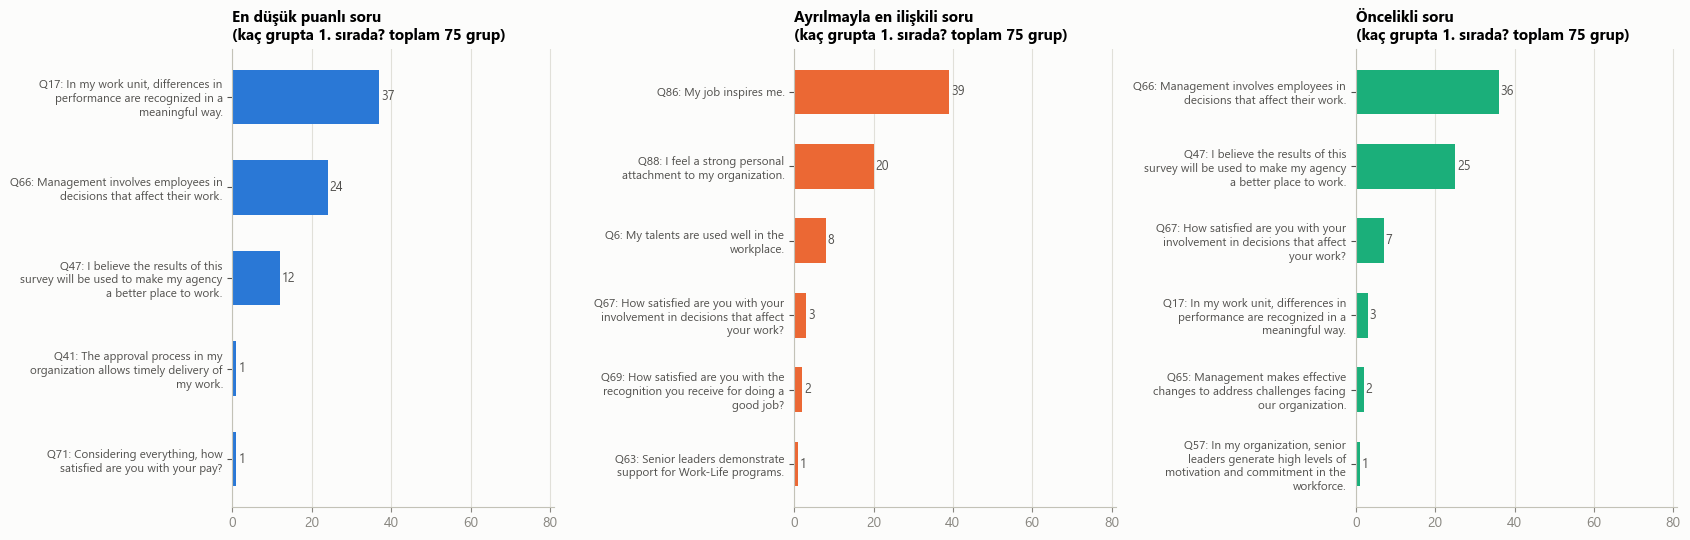

,ölçüt,madde,grup_sayısı,metin
0,Ayrılmayla en ilişkili,Q86,39,My job inspires me.
1,En düşük puanlı,Q17,37,"In my work unit, differences in performance are recognized in a me..."
2,Öncelikli,Q66,36,Management involves employees in decisions that affect their work.
3,Öncelikli,Q47,25,I believe the results of this survey will be used to make my agenc...
4,En düşük puanlı,Q66,24,Management involves employees in decisions that affect their work.
5,Ayrılmayla en ilişkili,Q88,20,I feel a strong personal attachment to my organization.
6,En düşük puanlı,Q47,12,I believe the results of this survey will be used to make my agenc...
7,Ayrılmayla en ilişkili,Q6,8,My talents are used well in the workplace.
8,Öncelikli,Q67,7,How satisfied are you with your involvement in decisions that affe...
9,Ayrılmayla en ilişkili,Q67,3,How satisfied are you with your involvement in decisions that affe...


In [6]:
rows = []
for gcol in GROUPINGS[1:]:
    t = summaries[gcol + " (Q46/Q70/Q72 hariç)"]
    for col, kind in [("en_düşük_soru", "En düşük puanlı"), ("ayrılmayla_en_ilişkili", "Ayrılmayla en ilişkili"),
                      ("öncelikli_soru", "Öncelikli")]:
        rows += [{"ölçüt": kind, "madde": v.split(" – ")[0]} for v in t[col]]
freq = pd.DataFrame(rows).value_counts().rename("grup_sayısı").reset_index()
freq["metin"] = freq["madde"].map(text_map)
n_groups = sum(len(summaries[g]) for g in GROUPINGS[1:])
print(f"Toplam grup sayısı: {n_groups}")

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Segoe UI", "DejaVu Sans"],
                     "font.size": 10, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": AXIS,
                     "xtick.color": MUTED, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True})
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, (kind, color) in zip(axes, zip(["En düşük puanlı", "Ayrılmayla en ilişkili", "Öncelikli"], SERIES)):
    t = freq[freq["ölçüt"] == kind].head(6)[::-1]
    ax.barh([fill(f"{q}: {text_map[q]}", 38) for q in t["madde"]], t["grup_sayısı"], color=color, height=0.6)
    for yy, v in enumerate(t["grup_sayısı"]):
        ax.text(v + 0.5, yy, str(v), va="center", fontsize=9, color=INK2)
    ax.set_xlim(0, n_groups * 1.08); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
    ax.set_title(f"{kind} soru\n(kaç grupta 1. sırada? toplam {n_groups} grup)")
plt.tight_layout(); kaydet("04_01_tekrar_eden_sorular")
freq

## 4. Isı haritası – ayrılmayla en ilişkili 15 soru × demografik gruplar (r)

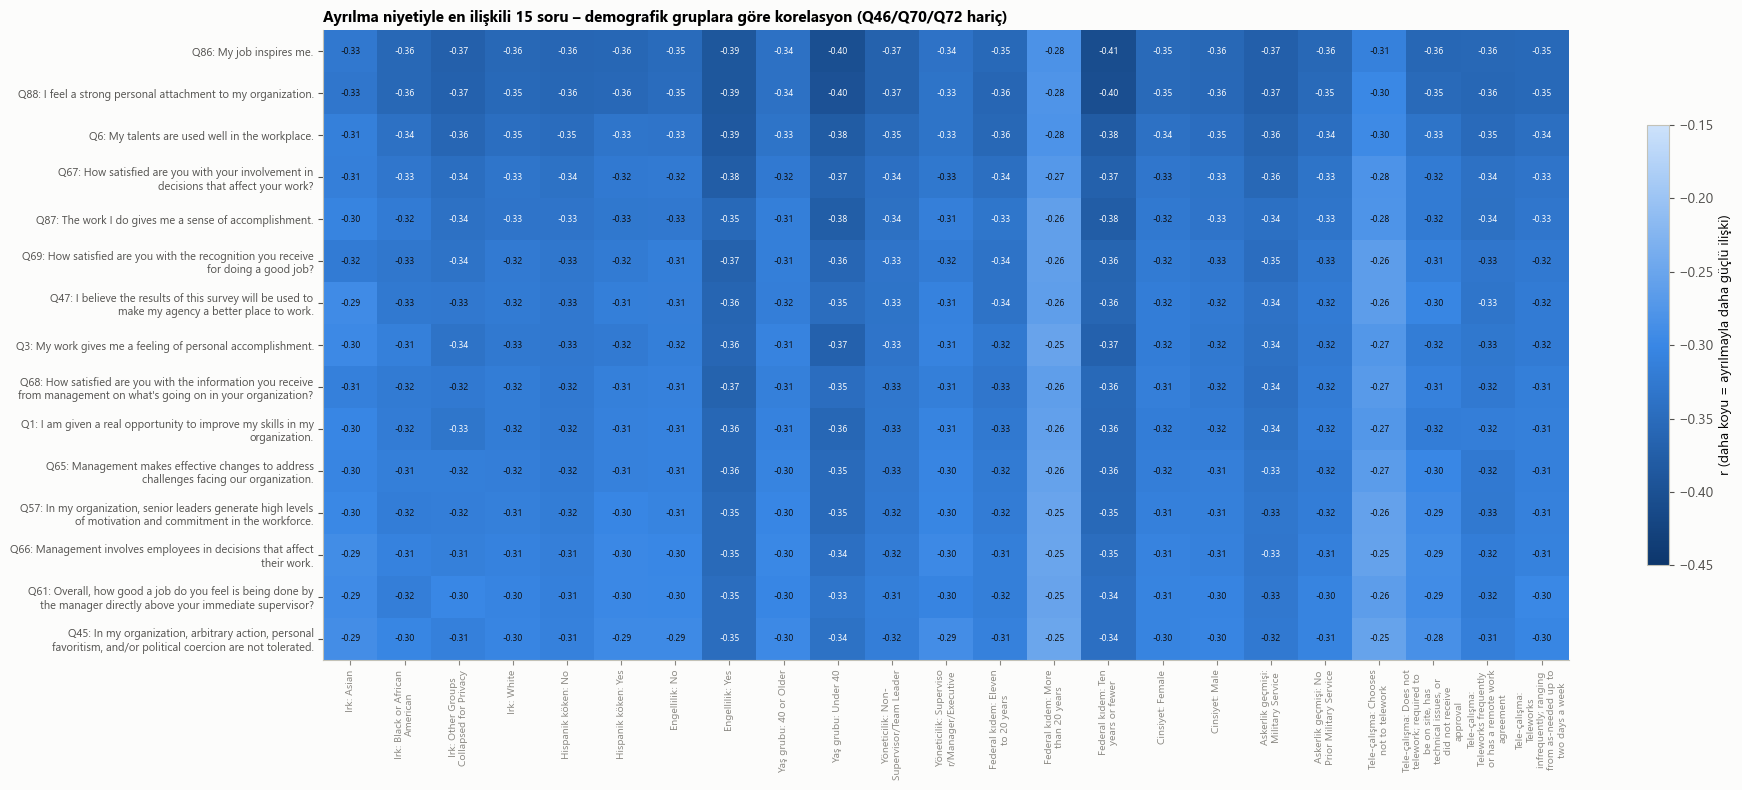

In [7]:
top15 = stats["TÜM"].query("madde not in @PROXY").nsmallest(15, "r")["madde"].tolist()
cols = []
for gcol in TR.values():
    s = stats[gcol]
    piv = s[s["madde"].isin(top15)].pivot(index="madde", columns="grup", values="r")
    piv = piv[[c for c in piv.columns if c != "(Eksik / Maskelenmiş)"]]
    piv.columns = [f"{gcol}: {c}" for c in piv.columns]
    cols.append(piv)
Hm = pd.concat(cols, axis=1).loc[top15]
seq = LinearSegmentedColormap.from_list("s", ["#0d366b", "#3987e5", "#cde2fb"])
fig, ax = plt.subplots(figsize=(19, 8))
im = ax.imshow(Hm.values, cmap=seq, vmin=-0.45, vmax=-0.15, aspect="auto"); ax.grid(False)
ax.set_yticks(range(len(Hm)), [fill(f"{q}: {text_map[q]}", 60) for q in Hm.index], fontsize=8)
ax.set_xticks(range(Hm.shape[1]), [fill(c, 22) for c in Hm.columns], rotation=90, fontsize=7.5)
for i in range(Hm.shape[0]):
    for j in range(Hm.shape[1]):
        v = Hm.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if v < -0.33 else INK)
fig.colorbar(im, ax=ax, shrink=0.7, label="r (daha koyu = ayrılmayla daha güçlü ilişki)")
ax.set_title("Ayrılma niyetiyle en ilişkili 15 soru – demografik gruplara göre korelasyon (Q46/Q70/Q72 hariç)")
plt.tight_layout(); kaydet("04_02_korelasyon_isi_haritasi")

In [8]:
OUT = TAB / "FEVS2024_grup_kritik_sorular.xlsx"
with pd.ExcelWriter(OUT) as xw:
    for k, t in summaries.items():
        t.to_excel(xw, sheet_name=k.replace(" (Q46/Q70/Q72 hariç)", "_haric")[:31])
    freq.to_excel(xw, sheet_name="Tekrar_eden_sorular", index=False)
    pd.concat(stats, names=["gruplama"]).reset_index(level=0).to_excel(xw, sheet_name="Tum_grup_madde_istat", index=False)
print("Kaydedildi:", OUT)

Kaydedildi: ~\fevs_proje\reports\tables\FEVS2024_grup_kritik_sorular.xlsx
